# Chapter 5: Classic Machine Learning Algorithms: KNN, K-Means, and the Decision Tree

This notebook collects the runnable examples of *Chapter 5: Classic Machine Learning Algorithms: KNN, K-Means, and the Decision Tree* from the textbook *Computational and Biological Intelligence* (A. Movasagh). Run the cells in order; each example is independent unless noted. Figures are also saved as PNG files in this folder.

## Learning objectives

After working through this notebook you should be able to:

- explain the difference between eager and lazy learning.
- use the uniform interface of the scikit-learn library.
- implement the KNN algorithm from scratch and choose the best k.
- implement the K-Means algorithm and determine the number of clusters with the elbow and silhouette methods.
- compute the entropy, Gini, and information gain criteria.
- build a decision tree, interpret it, and prevent it from overfitting.


In [1]:
%matplotlib inline

## Example 5.1: Comparing training and prediction times in eager and lazy learning

Script version: `example_5_1.py`

In [2]:
# Example 5.1: Eager versus lazy learning — comparing training and prediction times
import time
import numpy as np
from sklearn.datasets import make_classification
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
 
X, y = make_classification(n_samples=40000, n_features=20, random_state=0)
X_new = X[:5000]
 
for name, model in [("KNN (lazy)", KNeighborsClassifier(5, algorithm="brute")),
                    ("Decision tree (eager)", DecisionTreeClassifier(random_state=0))]:
    t0 = time.perf_counter(); model.fit(X, y);       t_fit = time.perf_counter() - t0
    t0 = time.perf_counter(); model.predict(X_new);  t_pred = time.perf_counter() - t0
    print(f"{name:<22} fit: {t_fit*1000:8.1f} ms | predict 5000 samples: {t_pred*1000:8.1f} ms")

KNN (lazy)             fit:      3.2 ms | predict 5000 samples:    419.5 ms


Decision tree (eager)  fit:   1438.6 ms | predict 5000 samples:      1.4 ms


## Example 5.2: Implementing KNN from scratch following the four steps of the algorithm

Script version: `example_5_2.py`

In [3]:
# Example 5.2: The KNN algorithm from scratch — exactly the four steps on the slide
import numpy as np
from collections import Counter
 
def knn_predict(X_train, y_train, x_new, k=3):
    # 1) distance from the new point to every training point (Euclidean)
    d = np.sqrt(((X_train - x_new) ** 2).sum(axis=1))
    # 2) sort the data by distance (ascending)
    order = np.argsort(d)
    # 3) choose the first k points as neighbors
    neighbors = order[:k]
    # 4) majority vote of the neighbors' labels
    vote = Counter(y_train[neighbors]).most_common(1)[0][0]
    return vote, d[neighbors]
 
# toy data: two features (e.g. hemoglobin, white-cell count), label 0 = healthy, 1 = anemic
X_train = np.array([[13.5, 7.0], [14.2, 6.5], [15.0, 8.1], [11.0, 6.9],
                    [10.2, 7.5], [9.8, 6.0], [12.9, 7.2], [10.9, 8.0]])
y_train = np.array([0, 0, 0, 1, 1, 1, 0, 1])
x_new = np.array([12.3, 7.6])
 
for k in (1, 3, 5):
    label, dist = knn_predict(X_train, y_train, x_new, k)
    print(f"k={k}: neighbor distances={dist.round(2)} -> predicted class {label}")

k=1: neighbor distances=[0.72] -> predicted class 0
k=3: neighbor distances=[0.72 1.34 1.46] -> predicted class 0
k=5: neighbor distances=[0.72 1.34 1.46 1.48 2.1 ] -> predicted class 1


## Example 5.3: The KNN decision boundary for k=1 and k=15

Script version: `example_5_3.py`

k= 1: training accuracy = 1.000


k=15: training accuracy = 0.887


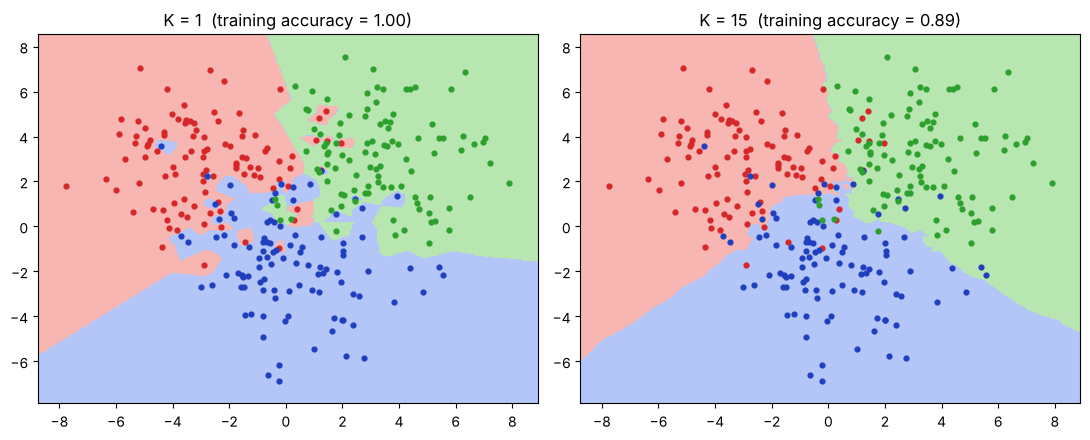

In [4]:
# Example 5.3: The KNN decision boundary for k=1 and k=15 (comparison with the slide)
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn.datasets import make_blobs
from sklearn.neighbors import KNeighborsClassifier
 
X, y = make_blobs(n_samples=300, centers=[(-3, 3), (0, -2), (3, 3)], cluster_std=2.0, random_state=4)
xx, yy = np.meshgrid(np.linspace(X[:, 0].min() - 1, X[:, 0].max() + 1, 300),
                     np.linspace(X[:, 1].min() - 1, X[:, 1].max() + 1, 300))
light = ListedColormap(["#f7b6b2", "#b3c6f7", "#b8e6b0"]); dark = ["#d62728", "#1f3fbf", "#2ca02c"]
 
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
for a, k in zip(ax, [1, 15]):
    m = KNeighborsClassifier(n_neighbors=k).fit(X, y)
    Z = m.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    a.contourf(xx, yy, Z, cmap=light)
    for c in range(3):
        a.scatter(*X[y == c].T, s=12, c=dark[c])
    a.set_title(f"K = {k}  (training accuracy = {m.score(X, y):.2f})")
    print(f"k={k:>2}: training accuracy = {m.score(X, y):.3f}")
plt.tight_layout(); plt.savefig("fig5_2.png", dpi=300)

## Example 5.4: Choosing the best k for breast cancer diagnosis

Script version: `example_5_4.py`

k=1  -> train acc 1.0 | val acc 0.965
Best k on validation: 6 | val acc 0.991
Test accuracy with best k: 0.974


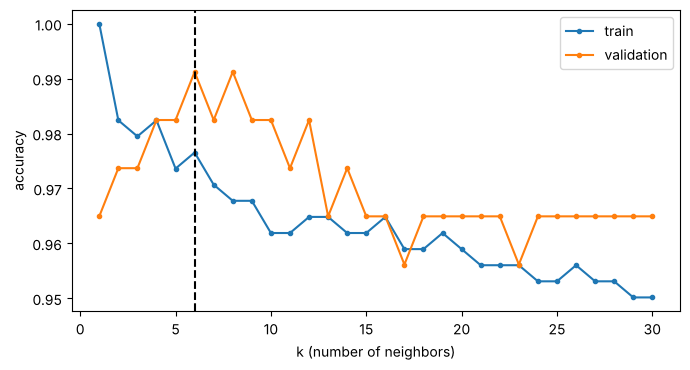

In [5]:
# Example 5.4: KNN with scikit-learn and choosing the best k with validation data
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
 
X, y = load_breast_cancer(return_X_y=True)
X_tmp, X_te, y_tmp, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=1)
X_tr, X_val, y_tr, y_val = train_test_split(X_tmp, y_tmp, test_size=0.25, stratify=y_tmp, random_state=1)
 
ks, tr_acc, val_acc = range(1, 31), [], []
for k in ks:
    m = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k)).fit(X_tr, y_tr)
    tr_acc.append(m.score(X_tr, y_tr)); val_acc.append(m.score(X_val, y_val))
 
best_k = ks[max(range(len(ks)), key=lambda i: val_acc[i])]
final = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=best_k)).fit(X_tmp, y_tmp)
print("k=1  -> train acc", round(tr_acc[0], 3), "| val acc", round(val_acc[0], 3))
print("Best k on validation:", best_k, "| val acc", round(max(val_acc), 3))
print("Test accuracy with best k:", round(final.score(X_te, y_te), 3))
 
plt.figure(figsize=(7, 3.8))
plt.plot(ks, tr_acc, "o-", ms=3, label="train"); plt.plot(ks, val_acc, "o-", ms=3, label="validation")
plt.axvline(best_k, ls="--", c="k"); plt.xlabel("k (number of neighbors)"); plt.ylabel("accuracy")
plt.legend(); plt.tight_layout(); plt.savefig("fig5_1.png", dpi=300)

## Example 5.5: Implementing K-Means from scratch

Script version: `example_5_5.py`

iteration 1: SSE =  4044.48
iteration 2: SSE =  1489.23
iteration 3: SSE =  1003.03
iteration 4: SSE =   791.44
iteration 5: SSE =   639.75
iteration 6: SSE =   590.33
iteration 7: SSE =   578.46
iteration 8: SSE =   578.01
Converged.


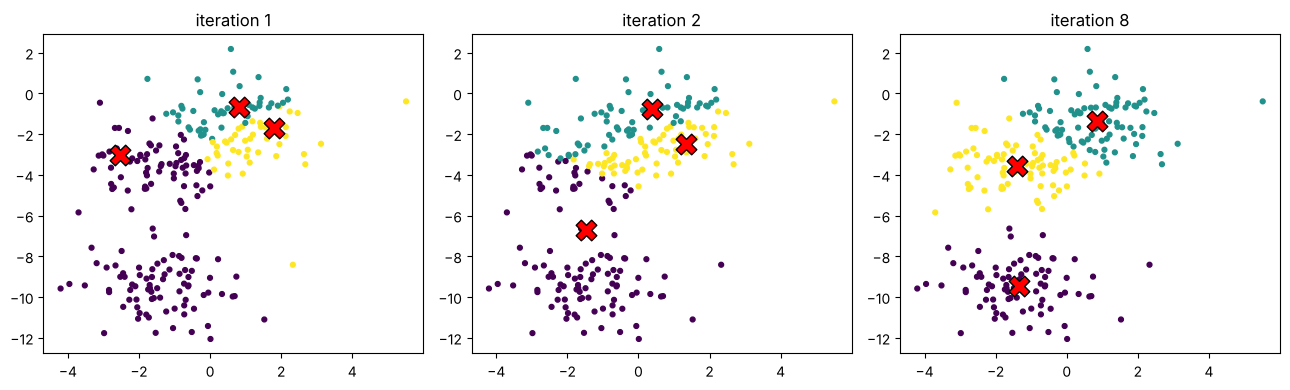

In [6]:
# Example 5.5: The K-Means algorithm from scratch, showing its steps
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
 
X, _ = make_blobs(n_samples=240, centers=3, cluster_std=1.1, random_state=2)
rng = np.random.default_rng(5)
k = 3
centers = X[rng.choice(len(X), k, replace=False)]        # 1) random initial centers
 
snapshots = []
for it in range(10):
    d = np.linalg.norm(X[:, None, :] - centers[None], axis=2)
    labels = d.argmin(1)                                 # 2) assign each point to nearest center
    snapshots.append((centers.copy(), labels.copy()))
    new_centers = np.array([X[labels == c].mean(0) for c in range(k)])   # 3) move to centroid
    sse = (d.min(1) ** 2).sum()
    print(f"iteration {it + 1}: SSE = {sse:8.2f}")
    if np.allclose(new_centers, centers):                # 5) stop when nothing changes
        print("Converged.")
        break
    centers = new_centers                                # 4) repeat
 
fig, ax = plt.subplots(1, 3, figsize=(13, 4))
for a, i in zip(ax, [0, 1, len(snapshots) - 1]):
    c, l = snapshots[i]
    a.scatter(*X.T, c=l, cmap="viridis", s=12); a.scatter(*c.T, c="red", marker="X", s=220, edgecolor="k")
    a.set_title(f"iteration {i + 1}")
plt.tight_layout(); plt.savefig("fig5_3.png", dpi=300)

## Example 5.6: The elbow method and the silhouette score for choosing k

Script version: `example_5_6.py`

k=2: inertia (SSE) =   8951.5 | silhouette = 0.647
k=3: inertia (SSE) =   3859.2 | silhouette = 0.734
k=4: inertia (SSE) =    871.8 | silhouette = 0.787
k=5: inertia (SSE) =    789.3 | silhouette = 0.666
k=6: inertia (SSE) =    710.3 | silhouette = 0.554
k=7: inertia (SSE) =    630.8 | silhouette = 0.440
k=8: inertia (SSE) =    562.2 | silhouette = 0.318
k=9: inertia (SSE) =    512.7 | silhouette = 0.333
Best k by silhouette: 4


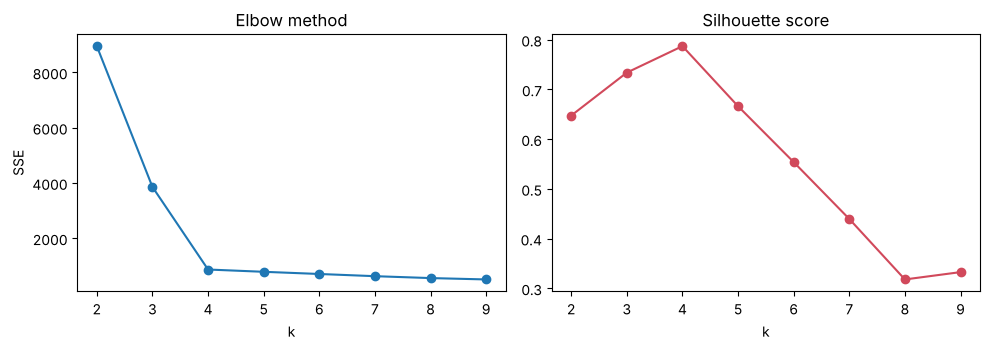

In [7]:
# Example 5.6: Choosing the number of clusters with the elbow method and the silhouette score
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
 
X, _ = make_blobs(n_samples=500, centers=4, cluster_std=1.0, random_state=10)
ks, inertia, sil = range(2, 10), [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(X)
    inertia.append(km.inertia_); sil.append(silhouette_score(X, km.labels_))
    print(f"k={k}: inertia (SSE) = {km.inertia_:8.1f} | silhouette = {sil[-1]:.3f}")
print("Best k by silhouette:", ks[sil.index(max(sil))])
 
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].plot(ks, inertia, "o-"); ax[0].set_title("Elbow method"); ax[0].set_xlabel("k"); ax[0].set_ylabel("SSE")
ax[1].plot(ks, sil, "o-", c="#d1495b"); ax[1].set_title("Silhouette score"); ax[1].set_xlabel("k")
plt.tight_layout(); plt.savefig("fig5_4.png", dpi=300)

## Example 5.7: Color segmentation of a histology image with K-Means

Script version: `example_5_7.py`

cluster 0: mean RGB = [135 102  71] | share = 30.1%
cluster 1: mean RGB = [170 148 128] | share = 32.0%
cluster 2: mean RGB = [216 215 215] | share = 37.9%


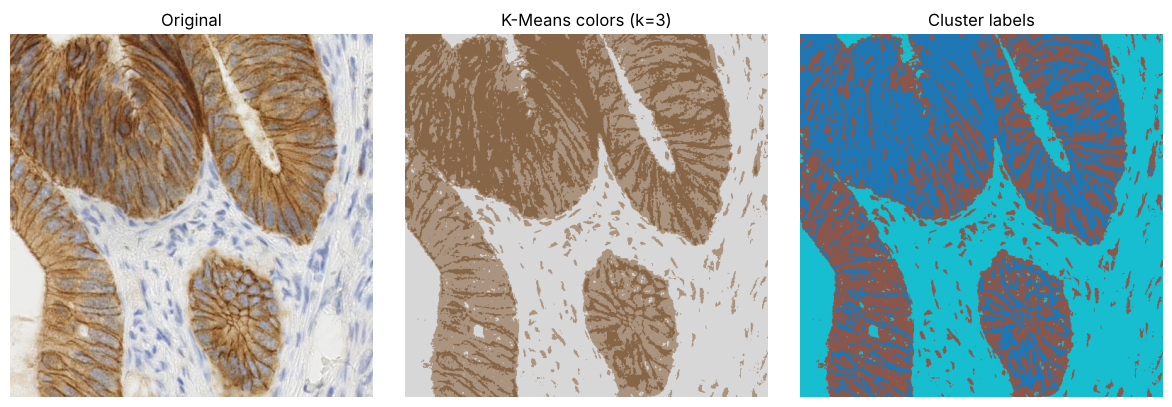

In [8]:
# Example 5.7: Segmenting a histology image with K-Means on pixel colors
import numpy as np
import matplotlib.pyplot as plt
from skimage import data
from sklearn.cluster import KMeans
 
img = data.immunohistochemistry() / 255.0
pixels = img.reshape(-1, 3)
km = KMeans(n_clusters=3, n_init=4, random_state=0).fit(pixels[::20])   # fit on a sample
labels = km.predict(pixels).reshape(img.shape[:2])
segmented = km.cluster_centers_[labels]
 
for c, center in enumerate(km.cluster_centers_):
    print(f"cluster {c}: mean RGB = {(center * 255).astype(int)} | share = {np.mean(labels == c):.1%}")
 
fig, ax = plt.subplots(1, 3, figsize=(12, 4))
ax[0].imshow(img); ax[0].set_title("Original")
ax[1].imshow(segmented); ax[1].set_title("K-Means colors (k=3)")
ax[2].imshow(labels, cmap="tab10"); ax[2].set_title("Cluster labels")
for a in ax: a.axis("off")
plt.tight_layout(); plt.savefig("fig5_5.png", dpi=300)

## Example 5.8: Computing entropy, Gini impurity, and information gain

Script version: `example_5_8.py`

In [9]:
# Example 5.8: Computing entropy, Gini impurity, and information gain by hand
import numpy as np
 
def entropy(counts):
    p = np.array(counts) / sum(counts); p = p[p > 0]
    return -(p * np.log2(p)).sum()
 
def gini(counts):
    p = np.array(counts) / sum(counts)
    return 1 - (p ** 2).sum()
 
parent = [9, 5]                       # 9 sick, 5 healthy patients
left, right = [6, 1], [3, 4]          # split by "fever = yes / no"
n = sum(parent)
ig = entropy(parent) - (sum(left) / n * entropy(left) + sum(right) / n * entropy(right))
print("Entropy parent:", round(entropy(parent), 3), "| Gini parent:", round(gini(parent), 3))
print("Entropy left/right:", round(entropy(left), 3), round(entropy(right), 3))
print("Information gain of the split:", round(ig, 3))

Entropy parent: 0.94 | Gini parent: 0.459
Entropy left/right: 0.592 0.985
Information gain of the split: 0.152


## Example 5.9: A decision tree for breast cancer diagnosis

Script version: `example_5_9.py`

max_depth=1     leaves=  2 train=0.930 test=0.888
max_depth=3     leaves=  8 train=0.977 test=0.916
max_depth=None  leaves= 18 train=1.000 test=0.902
|--- worst perimeter <= 106.10
|   |--- worst concave points <= 0.13
|   |   |--- area error <= 48.98
|   |   |   |--- class: 1
|   |   |--- area error >  48.98
|   |   |   |--- class: 0
|   |--- worst concave points >  0.13
|   |   |--- worst texture <= 26.00
|   |   |   |--- class: 1
|   |   |--- worst texture >  26.00
|   |   |   |--- class: 0
|--- worst perimeter >  106.10
|   |--- mean concave points <= 0.06
|   |   |--- worst texture <= 20.05
|   |   |   |--- class: 1
|   |   |--- worst texture >  20.05
|   |   |   |--- class: 0
|   |--- mean concave points >  0.06
|   |   |--- class: 0

Top features: [('worst perimeter', 0.691), ('mean concave points', 0.105), ('worst concave points', 0.101), ('worst texture', 0.077)]


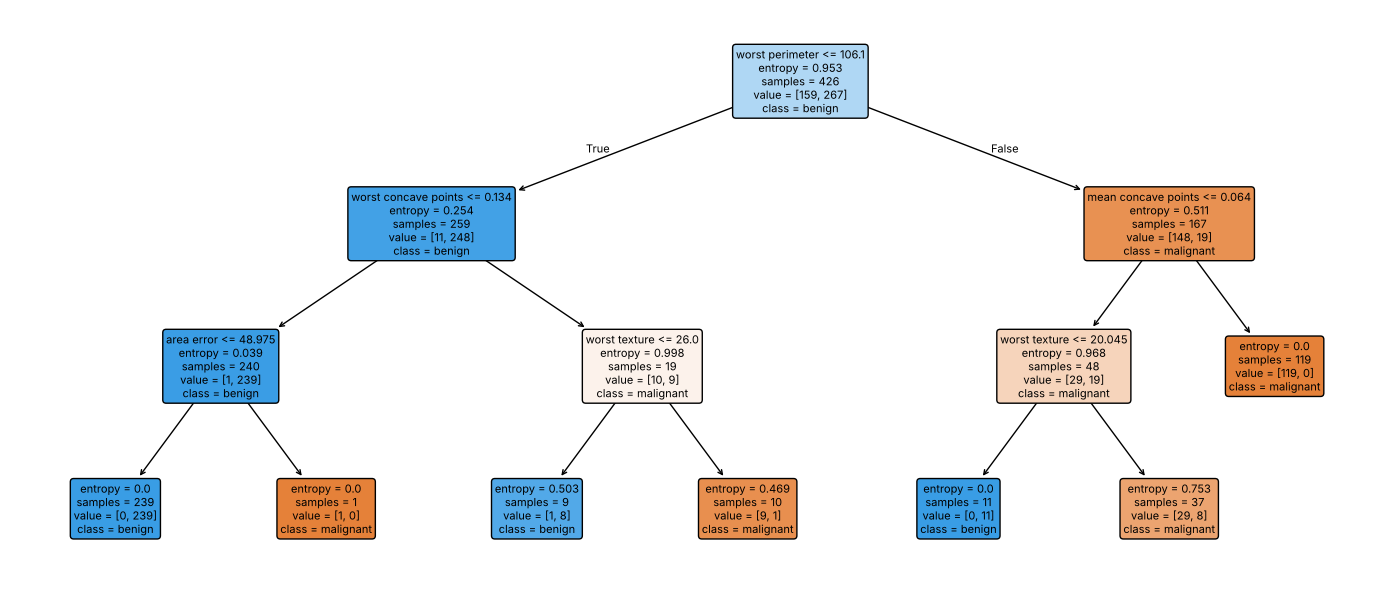

In [10]:
# Example 5.9: A decision tree for breast cancer diagnosis, displaying the tree and feature importances
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
 
data = load_breast_cancer()
X_tr, X_te, y_tr, y_te = train_test_split(data.data, data.target, test_size=0.25,
                                          stratify=data.target, random_state=0)
for depth in (1, 3, None):
    t = DecisionTreeClassifier(max_depth=depth, random_state=0).fit(X_tr, y_tr)
    print(f"max_depth={str(depth):<5} leaves={t.get_n_leaves():>3} "
          f"train={t.score(X_tr, y_tr):.3f} test={t.score(X_te, y_te):.3f}")
 
tree = DecisionTreeClassifier(max_depth=3, criterion="entropy", random_state=0).fit(X_tr, y_tr)
print(export_text(tree, feature_names=list(data.feature_names), decimals=2))
imp = sorted(zip(tree.feature_importances_, data.feature_names), reverse=True)[:4]
print("Top features:", [(str(n), round(float(v), 3)) for v, n in imp])
 
plt.figure(figsize=(14, 6))
plot_tree(tree, feature_names=data.feature_names, class_names=["malignant", "benign"],
          filled=True, rounded=True, fontsize=8)
plt.tight_layout(); plt.savefig("fig5_6.png", dpi=300)

## Example 5.10: Comparing KNN, the decision tree, and K-Means

Script version: `example_5_10.py`

In [11]:
# Example 5.10: Final comparison of KNN, the decision tree, and K-Means on one dataset
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
 
X, y = load_breast_cancer(return_X_y=True)
knn = make_pipeline(StandardScaler(), KNeighborsClassifier(7))
tree = DecisionTreeClassifier(max_depth=4, random_state=0)
for name, m in [("KNN (k=7)", knn), ("Decision tree", tree)]:
    s = cross_val_score(m, X, y, cv=5)
    print(f"{name:<14} 5-fold accuracy = {s.mean():.3f} ± {s.std():.3f}")
 
labels = KMeans(2, n_init=10, random_state=0).fit_predict(StandardScaler().fit_transform(X))
agree = max((labels == y).mean(), (labels != y).mean())
print(f"K-Means (no labels!) agreement with true diagnosis = {agree:.3f}")
print(f"Adjusted Rand index = {adjusted_rand_score(y, labels):.3f}")

KNN (k=7)      5-fold accuracy = 0.970 ± 0.009
Decision tree  5-fold accuracy = 0.916 ± 0.019
K-Means (no labels!) agreement with true diagnosis = 0.905
Adjusted Rand index = 0.654


## Example 5.11: Comparing a decision tree, a random forest, and an SVM, and tuning hyperparameters with GridSearchCV

Script version: `example_5_11.py`

In [12]:
# Example 5.11: Beyond the three algorithms — SVM and random forest on the breast cancer data
import numpy as np
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import cross_val_score, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
 
data = load_breast_cancer(); X, y = data.data, data.target
tree = DecisionTreeClassifier(random_state=0)
forest = RandomForestClassifier(n_estimators=300, random_state=0, n_jobs=-1)
svm = make_pipeline(StandardScaler(), SVC(kernel="rbf"))
for name, m in [("single decision tree", tree), ("random forest (300 trees)", forest), ("SVM (RBF kernel)", svm)]:
    s = cross_val_score(m, X, y, cv=5)
    print(f"{name:<26} 5-fold accuracy = {s.mean():.3f} ± {s.std():.3f}")
 
grid = GridSearchCV(svm, {"svc__C": [0.1, 1, 10, 100], "svc__gamma": ["scale", 0.01, 0.1]}, cv=5).fit(X, y)
print("Best SVM hyperparameters:", grid.best_params_, "| CV accuracy:", round(grid.best_score_, 3))
 
forest.fit(X, y)
top = np.argsort(forest.feature_importances_)[::-1][:5]
print("Random forest top-5 features:")
for i in top:
    print(f"   {data.feature_names[i]:<22} {forest.feature_importances_[i]:.3f}")

single decision tree       5-fold accuracy = 0.917 ± 0.016


random forest (300 trees)  5-fold accuracy = 0.963 ± 0.022
SVM (RBF kernel)           5-fold accuracy = 0.974 ± 0.015


Best SVM hyperparameters: {'svc__C': 10, 'svc__gamma': 0.01} | CV accuracy: 0.979


Random forest top-5 features:
   worst radius           0.125
   worst concave points   0.125
   worst perimeter        0.120


   worst area             0.110
   mean concave points    0.102
